# Encapsulation in Python

## Definition

**Encapsulation** is an OOP concept where we **bundle data (variables) and the methods that operate on that data together inside a class**.

It also helps us **control access to the data** and prevent it from being changed directly when we don't want that.

### Simple Definition

> **Encapsulation = Bundling data and methods together + controlling access to the data.**

---

# Real-World Example

Think about an **ATM**.

An ATM has data such as:

```text
PIN
Balance
```
And operations such as:

```text
Change PIN
Deposit
Withdraw
Check Balance
```

We don't want users to directly modify the balance like:
```python
atm.balance = 1000000
```
Instead, we want them to use controlled methods:
```python
atm.deposit(5000)
atm.withdraw(2000)
```
This is where `encapsulation` becomes useful.

### Example Without Encapsulation
```python
class Atm:

    def __init__(self):
        self.pin = "1234"
        self.balance = 5000


atm = Atm()

print(atm.balance)

atm.balance = 1000000

print(atm.balance)
```
### Output
```text
5000
1000000
```

The user was able to directly change the balance.

This is generally not desirable for something like an ATM.

In [1]:
class Atm():
    
    def __init__(self):
        self.pin = ""
        self.balance = 4000

sbi = Atm()

print(sbi.balance)

sbi.balance = 100000
print(sbi.balance)

4000
100000


# Encapsulation Using Private Attributes

Python allows us to indicate that an attribute should not be accessed directly by using double underscore `__`.
```python
class Atm:

    def __init__(self):
        self.__pin = "1234"
        self.__balance = 5000
```
Here:
```python
self.__pin
self.__balance
```
are private attributes (more precisely, attributes subject to Python's name-mangling mechanism).

Now we can provide methods to control how they are accessed.
```python
class Atm:

    def __init__(self):
        self.__pin = "1234"
        self.__balance = 5000

    def check_balance(self):
        return self.__balance

    def deposit(self, amount):
        self.__balance += amount
```
Now:
```python
atm = Atm()

print(atm.check_balance())

atm.deposit(2000)

print(atm.check_balance())
```
### Output
```text
5000
7000
```
Instead of directly changing:
```python
atm.__balance
```
we use:
```python
atm.deposit(2000)
```
The `class` controls how the balance is modified.

In [5]:
class Atm():
    
    def __init__(self):
        self.__pin = ""
        self.__balance = 4000
        
    def deposit(self, amount):
        self.__balance += amount
        
    def check_balance(self):
        return self.__balance
    
sbi = Atm()

print(sbi.check_balance())

sbi.deposit(6000)
print(sbi.check_balance())

4000
10000


# Understanding Encapsulation

Look at this class:
```python
class Atm:

    def __init__(self):
        self.__balance = 5000

    def deposit(self, amount):
        self.__balance += amount

    def withdraw(self, amount):
        if amount <= self.__balance:
            self.__balance -= amount

    def check_balance(self):
        return self.__balance
```
Here:

Data
```python
self.__balance
```
Methods that operate on the data
```python
deposit()
withdraw()
check_balance()
```
They are all bundled inside the `Atm` `class`.

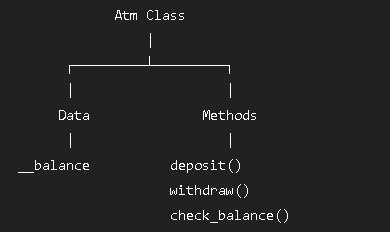

This is the idea of **encapsulation**.

# Why Is Encapsulation Useful?

### 1. Protecting Data

We can prevent users of the `class` from casually modifying important data directly.

For example:
```python
self.__balance
```
is intended to be accessed through controlled methods.

### 2. Controlling How Data Is Modified

Suppose we have:
```python
def withdraw(self, amount):
    if amount <= self.__balance:
        self.__balance -= amount
```
The method can check whether the withdrawal is valid before changing the balance.

Without this control, someone could potentially do:
```python
atm.balance = -50000
```
With **encapsulation**, we can decide exactly what operations are allowed.

### 3. Keeping Implementation Details Inside the Class

The user of the class doesn't need to know exactly how the balance is stored or modified.

They simply use:
```python
atm.deposit(5000)
atm.withdraw(2000)
atm.check_balance()
```
The internal implementation stays inside the class.

# `__` and **Encapsulation**

In Python, we commonly use:
```python
self.__balance
```
to indicate that an attribute is intended to be private.

For example:
```python
class Atm:

    def __init__(self):
        self.__balance = 5000
```
**The double underscore triggers name mangling.**

Python internally changes the attribute name to something similar to:
```python
_Atm__balance
```
Therefore, this:
```python
atm.__balance
```
will normally raise an `AttributeError`.

**However, Python's "private" attributes are not truly inaccessible like private fields in some other languages. The name-mangled form can still be accessed:**
```python
atm._Atm__balance
```
##### So Python's approach is better understood as:

***"This is an internal implementation detail; don't access it directly."**

rather than absolute security.

In [ ]:
class Atm:

    def __init__(self):
        self.__balance = 5000

sbi = Atm()

sbi.__balance = 10000  # this will create a new variable and store 10000 and wont edit the existing __varaible

print(sbi.__balance)
print(sbi._Atm__balance)

# But we can update the actual __balance aswell
sbi._Atm__balance = 12000
print(sbi._Atm__balance)

10000
5000
12000
